In [9]:
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
df = pd.read_csv("ecommerce_sales_real_world_practice.csv")
df["Date"] = pd.to_datetime(df["Date"])
df.info()
df.head()
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             24 non-null     datetime64[us]
 1   Product          24 non-null     str           
 2   Category         24 non-null     str           
 3   Units_Sold       24 non-null     int64         
 4   Unit_Price_USD   24 non-null     int64         
 5   Revenue_USD      24 non-null     int64         
 6   Region           24 non-null     str           
 7   Customer_Rating  24 non-null     float64       
 8   Returned_Units   24 non-null     int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(3)
memory usage: 1.8 KB


,Date,Units_Sold,Unit_Price_USD,Revenue_USD,Customer_Rating,Returned_Units
count,24,24.000000,24.000000,24.000000,24.000000,24.000000
mean,2026-03-30 00:00:00,31.458333,469.791667,12611.458333,4.429167,1.500000
min,2026-01-05 00:00:00,12.000000,100.000000,3100.000000,4.000000,1.000000
25%,2026-02-14 06:00:00,23.750000,100.000000,4475.000000,4.275000,1.000000
50%,2026-03-30 00:00:00,30.500000,375.000000,8250.000000,4.450000,1.000000
75%,2026-05-12 18:00:00,40.250000,700.000000,21000.000000,4.600000,2.000000
max,2026-06-22 00:00:00,52.000000,1000.000000,30000.000000,4.800000,3.000000
std,NaN,10.794440,357.905985,9427.921584,0.225503,0.589768


# Revenue and Customer rating Overtime

Goal: find out whether monthly revenue and average customer ratings change over time

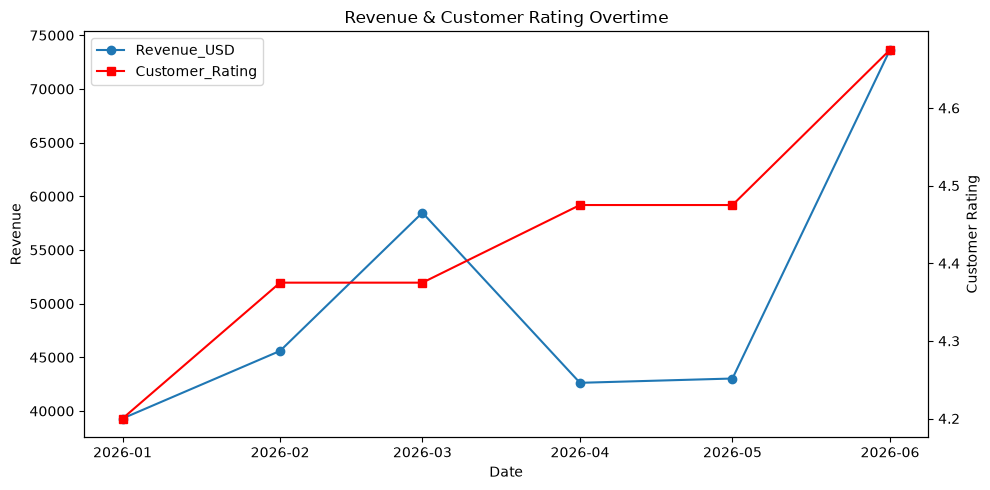

In [ ]:
revenue_and_ratings_overtime = (df.groupby(df["Date"].dt.to_period("M")).agg({
    "Revenue_USD": "sum",
    "Customer_Rating": "mean"
})
)

fig, ax = plt.subplots(figsize=(10, 5))

line1 = ax.plot(revenue_and_ratings_overtime.index.to_timestamp(),
                      revenue_and_ratings_overtime["Revenue_USD"],
                      marker='o',
                      label="Revenue_USD")
ax.set_xlabel('Date')
ax.set_ylabel('Revenue')

ax2 = ax.twinx()

line2 = ax2.plot(revenue_and_ratings_overtime.index.to_timestamp(),
                 revenue_and_ratings_overtime["Customer_Rating"],
                 marker='s',
                 color='r',
                 label="Customer_Rating")
ax2.set_ylabel("Customer Rating")

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc='upper left')

plt.title("Revenue & Customer Rating Overtime")
plt.tight_layout()

plt.show()

# Prodcut Revenue Contribution

Goal: Determine which products contributes the most to total revenue

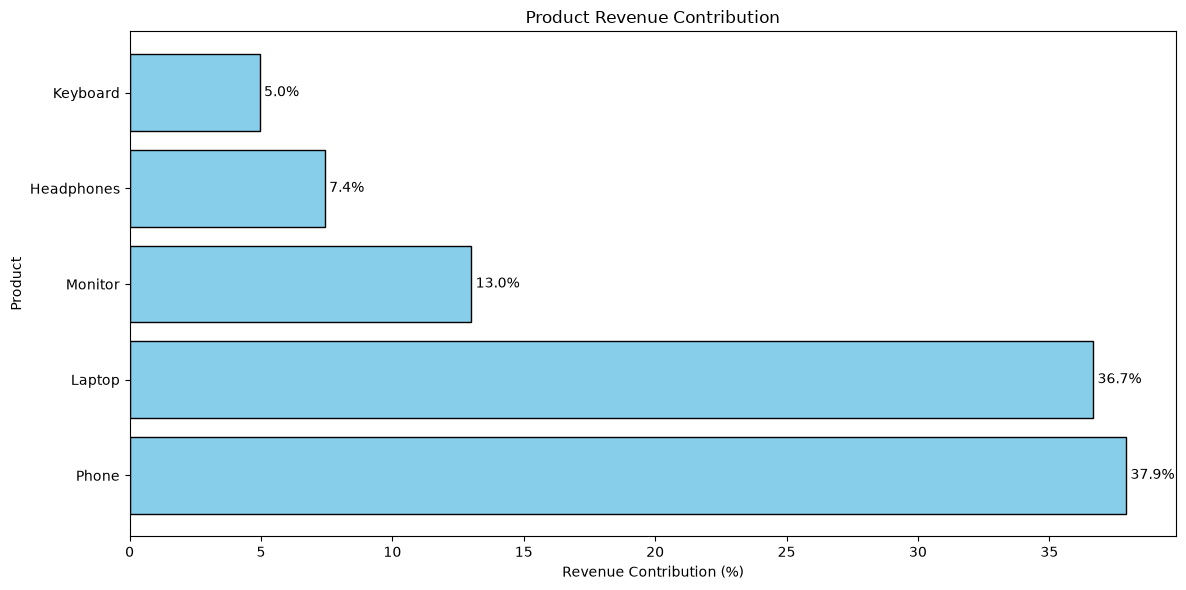

In [12]:
product_revenue = df.groupby("Product")["Revenue_USD"].sum().reset_index()
total_revenue = df["Revenue_USD"].sum()
product_revenue["Percentage_Contribution"] = (product_revenue["Revenue_USD"] / total_revenue) * 100
product_revenue = product_revenue.sort_values(by='Percentage_Contribution', ascending=False)

plt.figure(figsize=(12, 6))
bar = plt.barh(product_revenue["Product"],
               product_revenue["Percentage_Contribution"],
               color="skyblue",
               edgecolor='black')
plt.xlabel("Revenue Contribution (%)")
plt.ylabel("Product")
plt.title("Product Revenue Contribution")
plt.bar_label(bar,
               fmt="%1.1f%%",
              padding=3)
plt.tight_layout()

plt.show()



# Product Performance Report

Goal: Create a Dataframe named product_summary containing the metrics for each product

In [13]:
product_summary = df.groupby("Product").agg({
    "Units_Sold": "sum",
    "Revenue_USD": "sum",
    "Customer_Rating": "mean",
    "Returned_Units": "sum",
})
product_summary["Return_Rate"] = (product_summary["Returned_Units"] / product_summary["Units_Sold"]) * 100


# Dashboard

Text(0.5, 1.0, 'Rating vs Revenue')

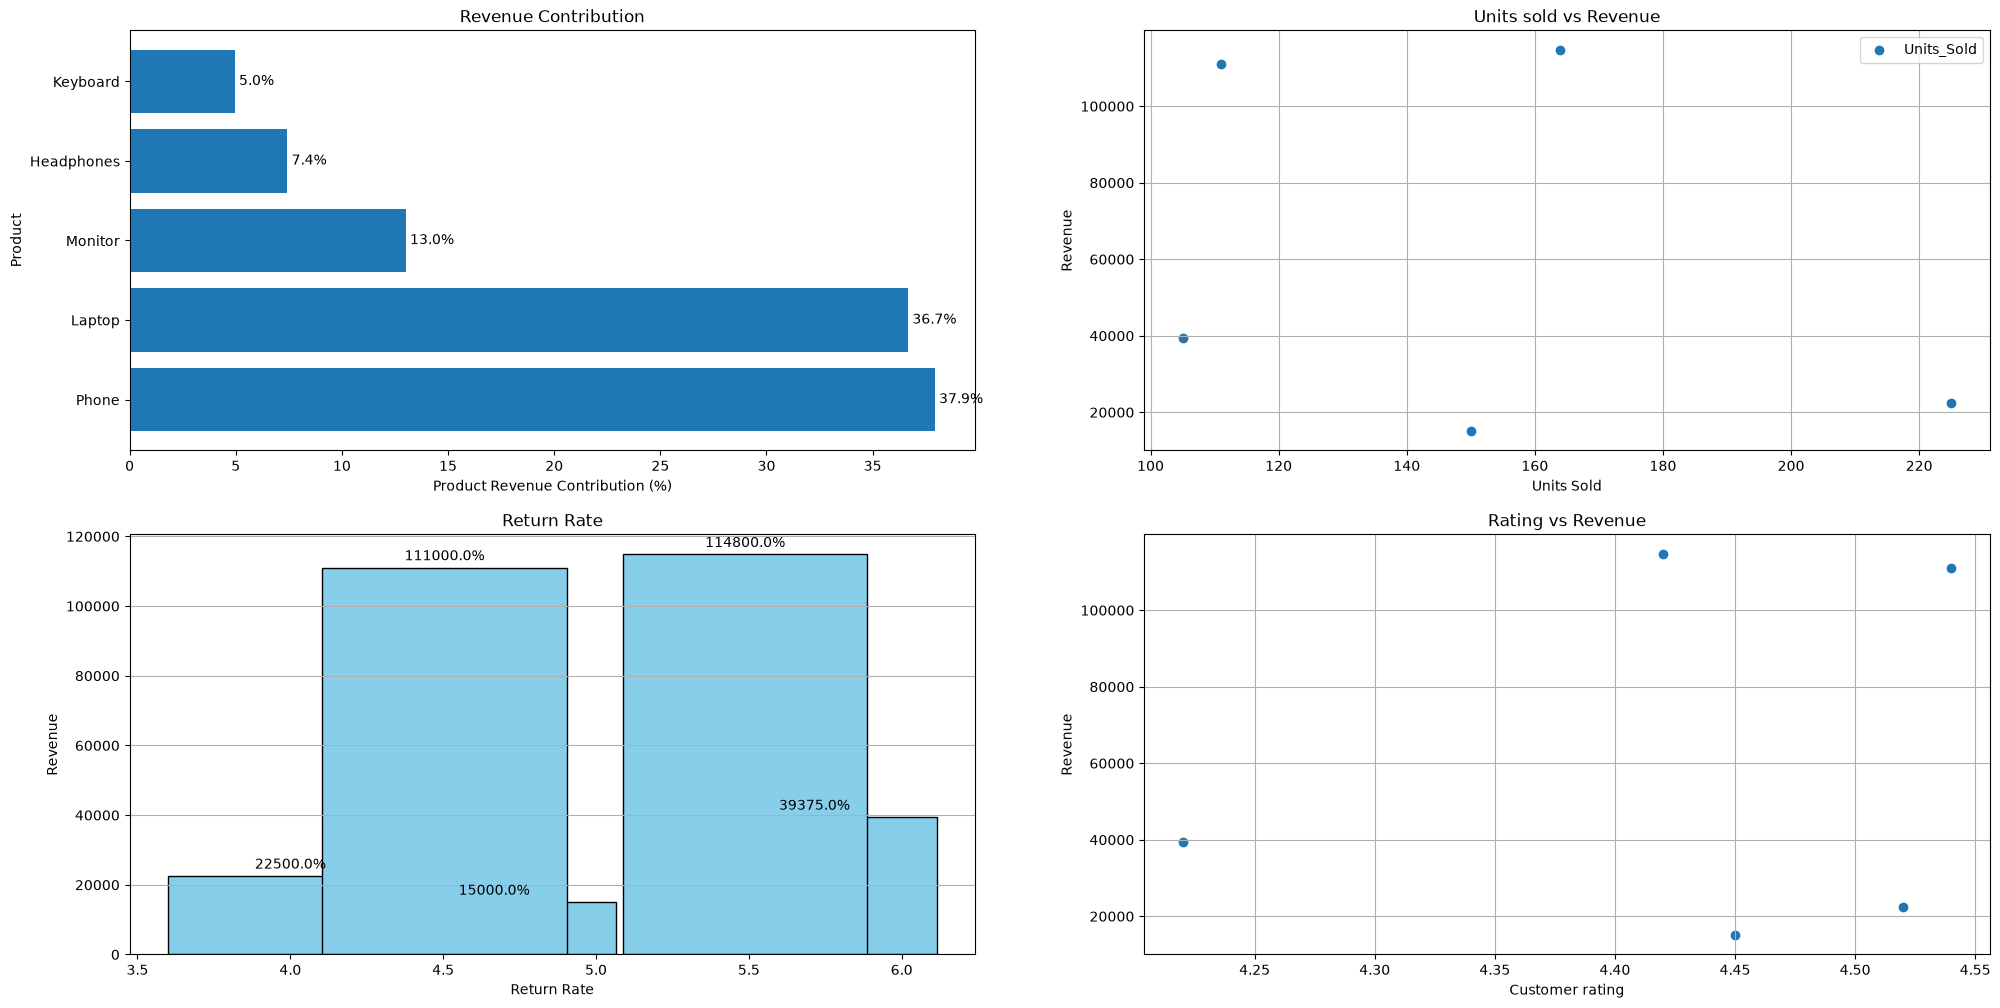

In [22]:
fig, ax = plt.subplots(2, 2, figsize=(24, 12))

bar = ax[0, 0].barh(product_revenue["Product"],
              product_revenue["Percentage_Contribution"])
ax[0, 0].set_xlabel("Product Revenue Contribution (%)")
ax[0, 0].set_ylabel("Product")
ax[0, 0].bar_label(bar,
                   fmt="%1.1f%%",
                   padding=3)
ax[0, 0].set_title("Revenue Contribution")

ax[0, 1].scatter(product_summary["Units_Sold"],
                 product_summary["Revenue_USD"],
                 label="Units_Sold")
ax[0, 1].set_xlabel("Units Sold")
ax[0, 1].set_ylabel("Revenue")
ax[0, 1].grid()
ax[0, 1].legend()
ax[0, 1].set_title("Units sold vs Revenue")

bar = ax[1, 0].bar(product_summary["Return_Rate"],
             product_summary["Revenue_USD"],
             color="skyblue",
             edgecolor="black")
ax[1, 0].set_xlabel("Return Rate")
ax[1, 0].set_ylabel("Revenue")
ax[1, 0].bar_label(bar, 
                   fmt="%1.1f%%",
                   padding=3)
ax[1, 0].grid(axis="y")
ax[1, 0].set_title("Return Rate")

ax[1, 1].scatter(product_summary["Customer_Rating"],
                 product_summary["Revenue_USD"])
ax[1, 1].set_xlabel("Customer rating")
ax[1, 1].set_ylabel("Revenue")
ax[1, 1].grid()
ax[1, 1].set_title("Rating vs Revenue")